In [1]:
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
import editdistance
rats = pd.read_csv(r"C:\Users\music\Desktop\SynADs\Helpful\synthetics_allfeats.csv", index_col=0)
synthseq = rats[rats['Ctrl'] == 0]
synthseq = synthseq[synthseq['NegCtrl'] == 0]

In [114]:
humansynth = pd.read_csv(r"C:\\Users\\music\\Downloads\\12Synthetics.csv", index_col=0)
humansynth.rename(columns={'AAseq': 'ADseq'}, inplace=True)
humansynth = humansynth[['ADseq']]
prich = 'PPLDPLFLDEDVPLFLDEDVPLFLDEDVPLFLDEFHQSLL'
aemextreme = 'VLEWEEEIDYDWDYHIGEDMLEMMMDTLEGFDLDMIELFG'

# Use pd.concat instead of append
humansynth = pd.concat([humansynth, pd.DataFrame({'ADseq': [prich, aemextreme]})], ignore_index=True)
humansynth

,ADseq
0,AELDSDDDFGFCLVPWEMFHLNLVDDWERGQLQTTRSAAS
1,GELLFDDFGFCYDDKFSSFVNEQEDFEFPELDFLGLEPFS
2,KQQEDATSSFPDNDDSSHSLNNSEAVEFEDFLKFSAFLDQ
3,FDIEDYLDDLDFSSLPPLSESFDLDSLLSGDFFDGLEEFA
4,DFLDSILKSPDEDPFEPDDFSGFSGGDRFTESLHYYSSLF
5,EFDDFNFEDYLTFFDETFDINELLGISSSNFLDDCYFSDI
6,AFTDSPNQLNNILGDEDDPLVPFDQFINLVSDNSNKNAFF
7,ELTFDEFIEQFTEEDITKLLDTPRSKPSSYFFNYDTSQDY
8,EEDEFYLDAIASTLGSPTTNSSSSQVGVLPSNLDITFLDF
9,HYADFFSHDEDAFLLFSPDDNAAGDDLSEFSESENFLFVG


In [2]:
def Calc_AlignmentDists(tempDF):
    mindists = {}
    minseqs = {}
    Seqlist = tempDF.ADseq.values
    AlignmentDists = np.zeros((len(Seqlist), len(Seqlist)))
    for i, seq1 in enumerate(Seqlist):
        tempdists = []
        tempseqs = []
        for j, seq2 in enumerate(Seqlist):
            if i > j:
                tempDist = editdistance.eval(seq1, seq2)
                tempdists.append(tempDist)
                tempseqs.append(seq2)
                AlignmentDists[i, j] = tempDist
        if i > 0 and tempdists:
            min_idx = np.argmin(tempdists)
            mindists[seq1] = tempdists[min_idx]
            minseqs[seq1] = tempseqs[min_idx]
    return AlignmentDists, mindists, minseqs

Synthetics_NoControls = synthseq.copy()
Synthetics_NoControls = Synthetics_NoControls.rename(columns={'AAseq': 'ADseq'})
Synthetics_NoControls.shape
SynthAlignmentDists, SynthminDistances, SynthminSeqs = Calc_AlignmentDists(Synthetics_NoControls)


seq_names = Synthetics_NoControls['ADseq'].values
editdist_df = pd.DataFrame(SynthAlignmentDists, index=seq_names, columns=seq_names)

In [115]:
HumanSynthAlignmentDists, HumanSynthminDistances, HumanSynthminSeqs = Calc_AlignmentDists(humansynth)
humansynth_seq_names = humansynth['ADseq'].values
humansynth_editdist_df = pd.DataFrame(HumanSynthAlignmentDists, index=humansynth_seq_names, columns=humansynth_seq_names)

In [118]:
humansynth_editdist_df

,AELDSDDDFGFCLVPWEMFHLNLVDDWERGQLQTTRSAAS,GELLFDDFGFCYDDKFSSFVNEQEDFEFPELDFLGLEPFS,KQQEDATSSFPDNDDSSHSLNNSEAVEFEDFLKFSAFLDQ,FDIEDYLDDLDFSSLPPLSESFDLDSLLSGDFFDGLEEFA,DFLDSILKSPDEDPFEPDDFSGFSGGDRFTESLHYYSSLF,EFDDFNFEDYLTFFDETFDINELLGISSSNFLDDCYFSDI,AFTDSPNQLNNILGDEDDPLVPFDQFINLVSDNSNKNAFF,ELTFDEFIEQFTEEDITKLLDTPRSKPSSYFFNYDTSQDY,EEDEFYLDAIASTLGSPTTNSSSSQVGVLPSNLDITFLDF,HYADFFSHDEDAFLLFSPDDNAAGDDLSEFSESENFLFVG,MPLSFKSSDEEDDDDLNMDQDYDFSFLDLTSPTSSLFPPL,ELFDLDFWWFQEQTSKIVLLLVGDGHGLELVPECCSPVEF,PPLDPLFLDEDVPLFLDEDVPLFLDEDVPLFLDEFHQSLL,VLEWEEEIDYDWDYHIGEDMLEMMMDTLEGFDLDMIELFG
AELDSDDDFGFCLVPWEMFHLNLVDDWERGQLQTTRSAAS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
GELLFDDFGFCYDDKFSSFVNEQEDFEFPELDFLGLEPFS,28.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
KQQEDATSSFPDNDDSSHSLNNSEAVEFEDFLKFSAFLDQ,35.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
FDIEDYLDDLDFSSLPPLSESFDLDSLLSGDFFDGLEEFA,31.0,29.0,33.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
DFLDSILKSPDEDPFEPDDFSGFSGGDRFTESLHYYSSLF,33.0,32.0,34.0,33.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EFDDFNFEDYLTFFDETFDINELLGISSSNFLDDCYFSDI,32.0,30.0,33.0,32.0,33.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AFTDSPNQLNNILGDEDDPLVPFDQFINLVSDNSNKNAFF,33.0,36.0,37.0,32.0,32.0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ELTFDEFIEQFTEEDITKLLDTPRSKPSSYFFNYDTSQDY,36.0,34.0,35.0,35.0,35.0,30.0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
EEDEFYLDAIASTLGSPTTNSSSSQVGVLPSNLDITFLDF,35.0,34.0,33.0,30.0,33.0,30.0,34.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0
HYADFFSHDEDAFLLFSPDDNAAGDDLSEFSESENFLFVG,35.0,33.0,33.0,34.0,31.0,31.0,34.0,36.0,31.0,0.0,0.0,0.0,0.0,0.0


[-0.5  0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5
 13.5 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5
 27.5 28.5 29.5 30.5 31.5 32.5 33.5 34.5 35.5 36.5 37.5 38.5 39.5 40.5]


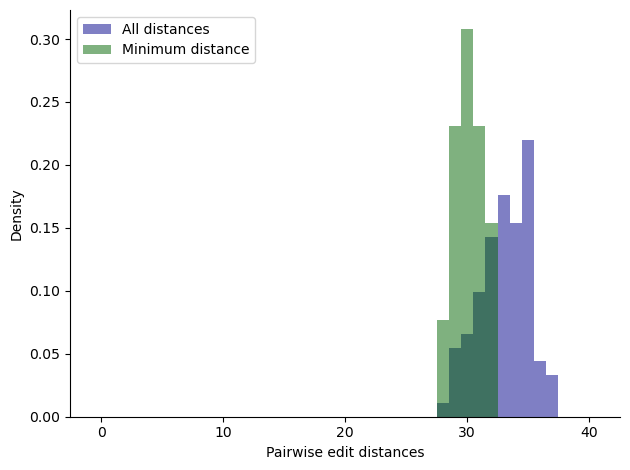

In [116]:
bins =np.linspace(-.5,40.5,42)
print(bins)
temp2 = np.ravel(humansynth_editdist_df)
temp3 = temp2[temp2>0]
plt.hist(temp3,bins,alpha=0.5,color='darkblue',label='All distances',density=1)
# plt.yscale('log')
# plt.ylim([3e-4,4e-1]),plt.yticks([1e-4, 1e-3,1e-2,1e-1])
plt.ylabel('Density')
plt.xlabel('Pairwise edit distances')

temp3 = HumanSynthminDistances.values()
plt.hist(temp3,bins,alpha=.5,color='darkgreen',label='Minimum distance',density=1)
# plt.yscale('log')
# plt.ylim([3e-4,4e-1]),plt.yticks(ticks=[1e-4, 1e-3,1e-2,1e-1],labels=[])
plt.legend()
plt.tight_layout()
sns.despine()
# plt.savefig('Figures/PaperFigs/Supp/Uniqu138_CAAD_EditDistances_HistSummary_linear.pdf')
plt.show()

In [117]:
nonzero_min = humansynth_editdist_df[humansynth_editdist_df > 0].min().min()
print("Nonzero minimum edit distance:", nonzero_min)

Nonzero minimum edit distance: 28.0


In [3]:
editdist_df.head()

,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,AAADGPSEPMMSTFGEEDFIEMDDLLMELERKDSFDSLEP,AAAEHDLYFNEIDVFKPGDSALVFDLENDDGYYLPVSDTP,AAAKGLLSPPLFMVDQMSFPLDISQGSLSLFPGFDDFGSF,AAAKNYMIEFDSGEELDFDLFVSIQDHMHILILCDSAPQE,AAALDYGFGYGYGLEEEVEEDDDYLFDPKFAFTSSVLLEA,...,YYSAFDCEDDDDEADKDSDWMLVGDDPWESFVNQADHLRQ,YYSAFDCEDDDDELFSLSYDDDCSKSNFVLDPSNYNNMWN,YYSAFDCEDDDDVDDEDEDDEADKDSDWMLVGDVPWDMFS,YYSAFDCEDDDDVDDLLDFSNEDIFSFLDLTSPTSIVSSE,YYSAFDCEDDDDVDDLLDFSSLPPLIDPSFEEVLEMHFYE,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,YYSSLGVEPWDLDGLFEFSRLLVDLNMDGFKIDWDYEVAE
AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,28.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,31.0,31.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,33.0,30.0,13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,32.0,30.0,29.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


[-0.5  0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5
 13.5 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5
 27.5 28.5 29.5 30.5 31.5 32.5 33.5 34.5 35.5 36.5 37.5 38.5 39.5 40.5]


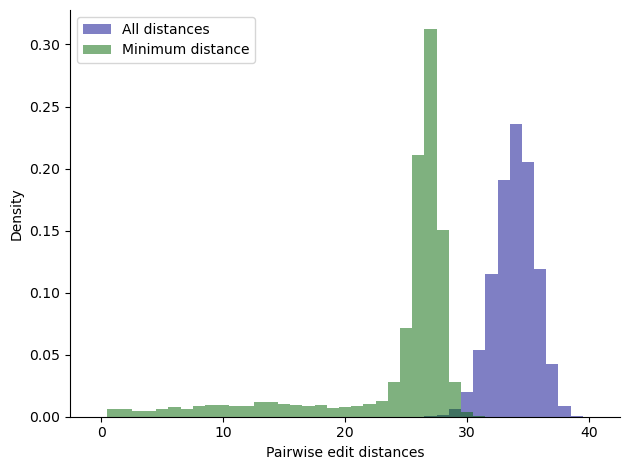

In [4]:
bins =np.linspace(-.5,40.5,42)
print(bins)
temp2 = np.ravel(SynthAlignmentDists)
temp3 = temp2[temp2>0]
plt.hist(temp3,bins,alpha=0.5,color='darkblue',label='All distances',density=1)
# plt.yscale('log')
# plt.ylim([3e-4,4e-1]),plt.yticks([1e-4, 1e-3,1e-2,1e-1])
plt.ylabel('Density')
plt.xlabel('Pairwise edit distances')

temp3 = SynthminDistances.values()
plt.hist(temp3,bins,alpha=.5,color='darkgreen',label='Minimum distance',density=1)
# plt.yscale('log')
# plt.ylim([3e-4,4e-1]),plt.yticks(ticks=[1e-4, 1e-3,1e-2,1e-1],labels=[])
plt.legend()
plt.tight_layout()
sns.despine()
# plt.savefig('Figures/PaperFigs/Supp/Uniqu138_CAAD_EditDistances_HistSummary_linear.pdf')
plt.show()

In [5]:
min_dist_df = pd.DataFrame(
    [(seq, SynthminDistances[seq], SynthminSeqs[seq]) for seq in SynthminDistances],
    columns=['Sequence', 'MinDistance', 'ClosestSequence']
)
min_dist_df

,Sequence,MinDistance,ClosestSequence
0,AAAAASDHSDVNDIIELGGLSNRLYDFYSDLEDIENDIAV,28,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE
1,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF,31,AAAAAIACELRTDNYFEYPDLSILDALDNDSDETMSLIDE
2,AAADGASFSDDTDEDLYKYDPWELPSKASFGEQEWYFFSP,13,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF
3,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN,29,AAADGASFSDDTDEDLYKYDPWDLPGLSVIKTDDPEWFFF
4,AAADGPSEPMMSTFGEEDFIEMDDLLMELERKDSFDSLEP,27,AAADGPDCDTREFCELRDSLLWNESCFLLDDDKRFDVSEN
...,...,...,...
16764,YYSDDIMLDLGVDLSNFQFDFRYFGLDSPLSPPWNEDDDS,26,SDCDGLCDLGTESLCHIFDYDELPQDSLLSWLPDSVDDDQ
16765,YYSEQSCYLDLDLDLDITFLDFSQFLEQLLQSKNDPLVSE,25,RATSTSIDLLLDFVGADSYFLDSFLMENDLFRAPDPNVEE
16766,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS,14,NDFSTADFQFDLNFPPLDCVDLVATLSEKFKSFSQLLLPY
16767,YYSEQSCYLNFPPLDMFPALPSDLSGWVESMLSELNNPAS,19,YYSEQSCYLNFPPLDCVDLVATLSEKFKSFSQLLLDFPIS


In [72]:
min_dist_df_merge = pd.merge(min_dist_df, rats, left_on='Sequence', right_on='AAseq', how='left')
min_dist_df_merge.drop(columns=['AAseq'], inplace=True)
min_dist_df_merge.rename(columns={'Sequence': 'AAseq'}, inplace=True)
min_dist_df_merge.to_csv(r"C:\Users\music\Downloads\Synthetics_min_edit_dist.csv")

In [73]:
min_dist_df_merge[min_dist_df_merge['MinDistance'] == 1].head(30)

,AAseq,MinDistance,ClosestSequence,OriginalIndices,ReplicateActivities,Activity,StdDev,NumReps,Ctrl,NegCtrl,...,TADA,TADA Score,# Models Predicted,# Models Predicted (ADPredNoKotha),# Models Predicted (all 5),Kappa,Omega,OmegaWFY_DE,OmegaWFYL_DE,OmegaWF_D
948,DAGLMGPLFRVSVEDIETGDDEGDMMLVGDVPWEMFVDSC,1,DAGLMGPLFRVSVEDIETGDDEGDMMLAGDVPWEMFVDSC,"[21302, 44302]","[254018.6632536616, 257732.34192173]",255875.502588,NaN,2,0,0,...,True,0.615,2.0,1.0,2.0,0.268403,0.078314,0.299507,0.307386,0.248786
1216,DELCRQSFDPLDFDVIDDEDDMMMVGDVPWDMFSSSCDAF,1,DELCRQSFDPLDFDVIDDEDDMMMVGDIPWDMFSSSCDAF,"[23279, 32882, 47986]","[249813.88028230856, 213600.72417943671, 25604...",239819.596926,22918.903648,3,0,0,...,True,0.677,4.0,3.0,4.0,0.283490,0.133338,0.240529,0.213243,0.170985
1220,DELCRQSFDPLDFDVIDDEDIETGDDEGDRMLVGDVPWQM,1,DELCRQSFDPLDFDVIDDEDIETGDDEGDMMLVGDVPWQM,"[18076, 21619, 32841, 37347]","[36899.96823598127, 44912.23353829298, 40968.7...",40407.699410,3432.034275,4,0,0,...,False,0.579,1.0,0.0,1.0,0.307963,0.039148,0.328704,0.292942,0.188124
1350,DFSDSVLKYINDMLMEEDLEWLSQFVDDSFSDFPANPLGG,1,DFSDSVLKYINDMLMEEDLEWLSNFVDDSFSDFPANPLGG,"[39249, 40082, 53964]","[167728.46782779176, 138481.08653117254, 15733...",154513.293541,14825.791149,3,0,0,...,True,0.687,4.0,4.0,5.0,0.261461,0.089468,0.150600,0.067616,0.076980
1428,DGSSSMSELPFDFSFDNSDDFFEQILGLSNFIPTICPPPS,1,DGSSSMSELPFDFSFDNSDDFFEQILGLSNFIPTICPPPF,[55940],[243798.07453543812],243798.074535,NaN,1,0,0,...,True,0.643,3.0,3.0,3.0,0.273072,0.235014,0.064437,0.096134,0.090206
1891,DQIFCENDDIFDVADLRDEIVKLPSLGTVGDFSDDLLDLS,1,DQIFCENDDIFDVADLRDEIVKLPSLGTVGDFSDDLLDFS,[30494],[33333.58615254384],33333.586153,NaN,1,0,0,...,True,0.669,3.0,2.0,3.0,0.205524,0.083212,0.167801,0.076331,0.131473
1993,DSSSSSYSLASTSLDQNMDEFLDFSDTEFEEIGSEGGASG,1,ASSSSSYSLASTSLDQNMDEFLDFSDTEFEEIGSEGGASG,"[10935, 17788, 28967, 31542]","[25961.289768138, 29178.467245373875, 27845.68...",28226.511456,1737.088513,4,0,0,...,False,0.594,2.0,1.0,2.0,0.243909,0.340601,0.091713,0.115809,0.101154
2065,DVDSSLSSYLDDDNEWVLLTCEADLEECQKIVLDPSYSDQ,1,DVDSSLSSYLDDDNEWVLLTCDADLEECQKIVLDPSYSDQ,"[4279, 27010]","[28735.45874619829, 28043.71372051972]",28389.586233,NaN,2,0,0,...,True,0.627,3.0,2.0,3.0,0.243826,0.165258,0.198632,0.105298,0.189975
2066,DVDSSLSSYLDDDQEWVLLTCEADLEECQKIVLDPSYSDQ,1,DVDSSLSSYLDDDNEWVLLTCEADLEECQKIVLDPSYSDQ,"[17161, 26481]","[20277.15768956374, 18731.74791883992]",19504.452804,NaN,2,0,0,...,True,0.625,3.0,2.0,3.0,0.243826,0.165258,0.198632,0.105298,0.189975
2836,EHLKGILSGDFFDDLSYLDDDNEWVLLTCDADLQECLEIP,1,EHLKGILSGDFFDDLSYLDDDKEWVLLTCDADLQECLEIP,"[5123, 9093, 35490, 36918, 44726, 49585]","[42493.534319981576, 75578.56227580676, 57365....",63853.206510,12173.814933,6,0,0,...,True,0.666,4.0,4.0,5.0,0.194359,0.109823,0.139182,0.066002,0.231009


In [23]:
min_dist_df_merge[min_dist_df_merge['MinDistance'] < 10].shape[0]

991

In [28]:
min_dist_df_merge[min_dist_df_merge['MinDistance'] < 10][min_dist_df_merge[min_dist_df_merge['MinDistance'] < 10]['ClosestSequence'].duplicated()][['AAseq', 'ClosestSequence', 'MinDistance']].head(50)

,AAseq,ClosestSequence,MinDistance
16,AADFADFDFSFDNSFGDMSFMEEKHQVSNNNNNQYASSSP,AADFADFDFSFDNSFGDMSFMEEKHQVSNNNNNNAALPEI,6
1131,DDMSMFMFMDPLSSAFDYPFLEALQSSTERSSSSSSSSTY,DDMSMFMFMDPLSSAFDYPFLEALQSSTERSSSSAAAVMY,5
1512,DISNSNKDIFLDRFNEALHYYSSLSSYLDDDVDDLDLSLR,DISNSNKDIFLDRFNEALHYYSSLSSYLDDDKEWVLLTCE,8
1517,DISNSNKDIFLDRFTESLHYYSSLFDSLEDLDSLMSTPMS,DISNSNKDIFLDRFNEALHYYSTLFDSLEDLDSLMSTPMS,3
1519,DISNSNKDIFLDRFTESLHYYSSLSSYLDDDNEWVLLTCE,DISNSNKDIFLDRFNEALHYYSSLSSYLDDDKEWVLLTCE,3
1573,DLACVTAINSSPPLFSDDDVFDFLVDIVPREDEEESGADF,DLACVTAINSSPPLFSDDDVFDFLVDIIPRDEESEPIYED,8
2201,EAEISFLEAQIDALDRDFCNILSDDFFDFDLSEPASPKIN,CVKTSFLEAQIDALDRDFCNILSDDFFDFDLSEPASPKIN,4
2224,EALQEIIDSSSSSLELLGILNDNWSDLPLWYDDLIEMKPP,ASAPNDLFSSSSSLELLGILNDNWSDLPLWYDDLIEMKPP,8
2537,EEEEEEEEDLSSSSLISGGVAPSDDAAHLEWLSNFVDDSF,AMVVKEEDMFSSSSLISGGVAPSDDAAHLEWLSNFVDDSF,8
2687,EEVTVVEEEDENTLHRSNDFSDSGFDEIGSFGLRKFPSVE,DDLGVVEEEDENTLHRSNDFSDSGFDEIGSFGLRKFPSVE,4


<Axes: xlabel='MinDistance', ylabel='State Size'>

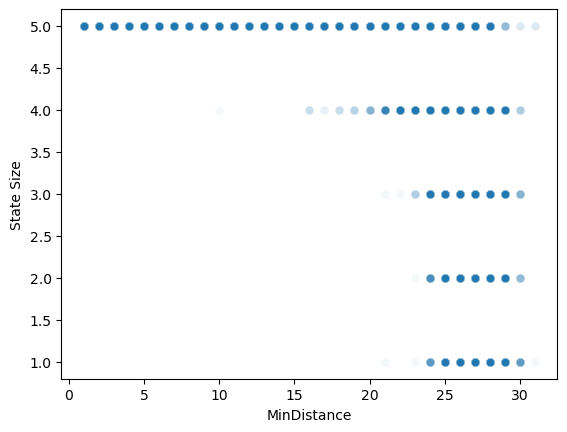

In [9]:
sns.scatterplot(data=min_dist_df_merge, x='MinDistance', y='State Size', alpha=0.05)

(0.0, 40.0)

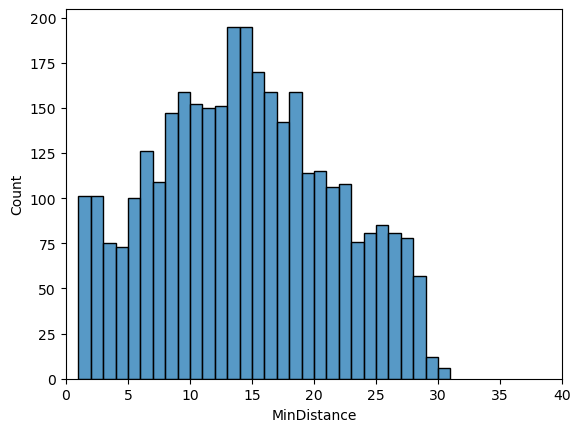

In [82]:
sns.histplot(min_dist_df_merge[min_dist_df_merge['State Size'] == 5]['MinDistance'], bins=30, kde=False)
plt.xlim(0,40)

(0.0, 40.0)

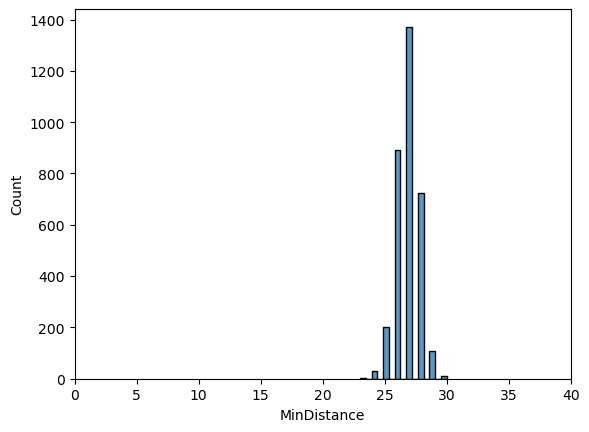

In [88]:
sns.histplot(min_dist_df_merge[min_dist_df_merge['State Size'] == 2]['MinDistance'], bins=15, kde=False)
plt.xlim(0,40)

In [101]:
print(min_dist_df_merge.shape)
print(min_dist_df_merge[min_dist_df_merge['State Size'] == 1].shape)

(16769, 57)
(3364, 57)


C:\Users\music\AppData\Local\Temp\ipykernel_50048\2859054135.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  blues = cm.get_cmap('Blues', 5)


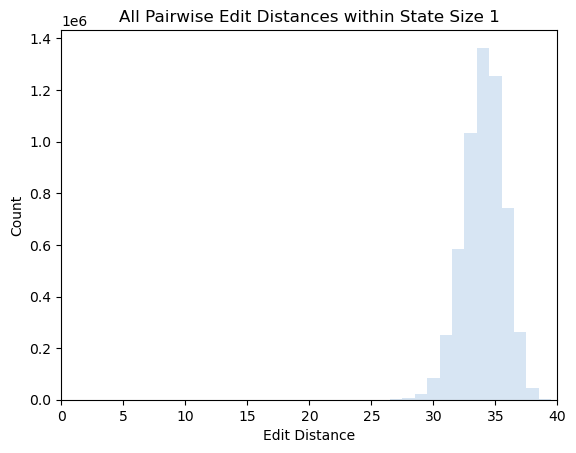

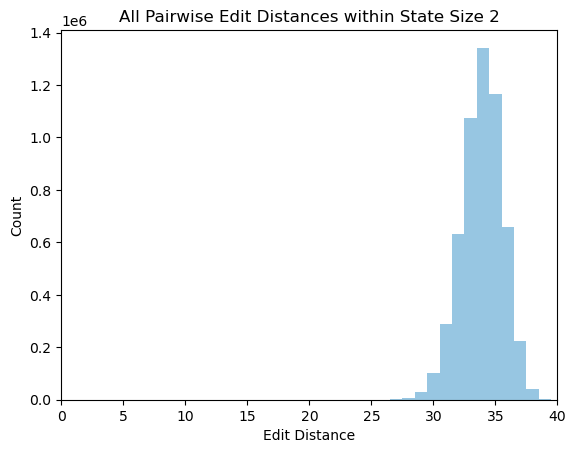

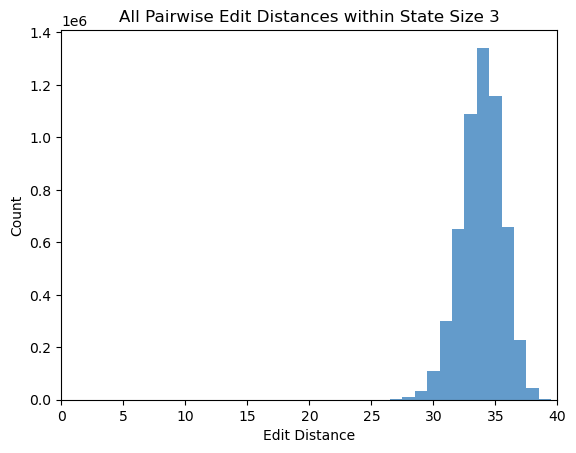

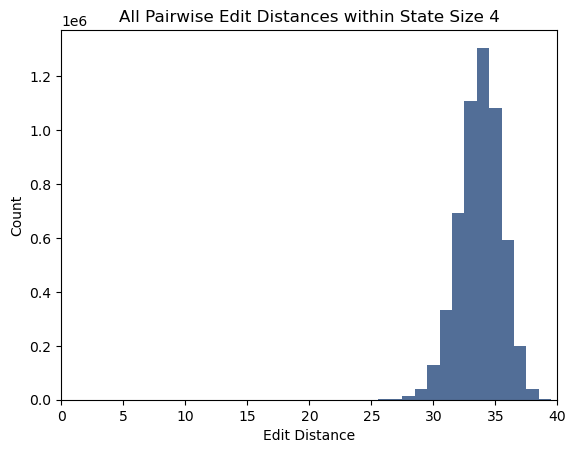

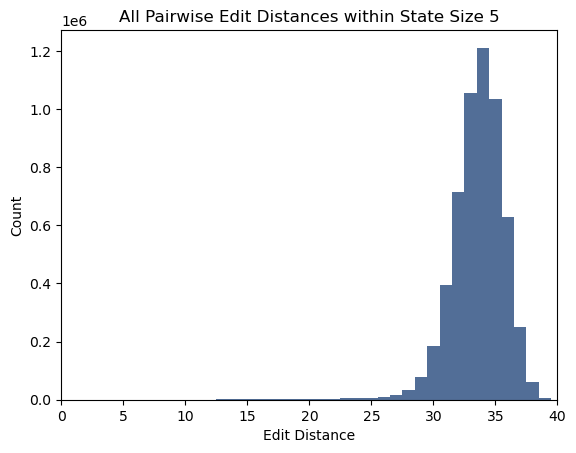

In [80]:
state5_seqs = synthseq[synthseq['State Size'] == 5]['AAseq'].values
state5_editdist_df = editdist_df.loc[state5_seqs, state5_seqs]
state4_seqs = synthseq[synthseq['State Size'] == 4]['AAseq'].values
state4_editdist_df = editdist_df.loc[state4_seqs, state4_seqs]
state3_seqs = synthseq[synthseq['State Size'] == 3]['AAseq'].values
state3_editdist_df = editdist_df.loc[state3_seqs, state3_seqs]
state2_seqs = synthseq[synthseq['State Size'] == 2]['AAseq'].values
state2_editdist_df = editdist_df.loc[state2_seqs, state2_seqs]
state1_seqs = synthseq[synthseq['State Size'] == 1]['AAseq'].values
state1_editdist_df = editdist_df.loc[state1_seqs, state1_seqs]

# Get the lower triangle values, excluding the diagonal
dists5 = state5_editdist_df.where(np.tril(np.ones(state5_editdist_df.shape), k=-1).astype(bool)).stack().values
dists4 = state4_editdist_df.where(np.tril(np.ones(state4_editdist_df.shape), k=-1).astype(bool)).stack().values
dists3 = state3_editdist_df.where(np.tril(np.ones(state3_editdist_df.shape), k=-1).astype(bool)).stack().values
dists2 = state2_editdist_df.where(np.tril(np.ones(state2_editdist_df.shape), k=-1).astype(bool)).stack().values
dists1 = state1_editdist_df.where(np.tril(np.ones(state1_editdist_df.shape), k=-1).astype(bool)).stack().values

blues = cm.get_cmap('Blues', 5)

plt.hist(dists1, color=blues(0.2), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
# plt.ylim(0,4)
plt.title('All Pairwise Edit Distances within State Size 1')
plt.show()
plt.hist(dists2, color=blues(0.4), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
# plt.ylim(0,1.4)
plt.title('All Pairwise Edit Distances within State Size 2')
plt.show()
plt.hist(dists3, color=blues(0.6), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
# plt.ylim(0,4)
plt.title('All Pairwise Edit Distances within State Size 3')
plt.show()
plt.hist(dists4, color=blues(0.8), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
# plt.ylim(0,4)
plt.title('All Pairwise Edit Distances within State Size 4')
plt.show()
plt.hist(dists5, color=blues(0.99), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
# plt.ylim(0,4)
plt.title('All Pairwise Edit Distances within State Size 5')
plt.show()

C:\Users\music\AppData\Local\Temp\ipykernel_50048\100761862.py:8: RuntimeWarning: All-NaN slice encountered
  min_dist = np.nanmin(dists)


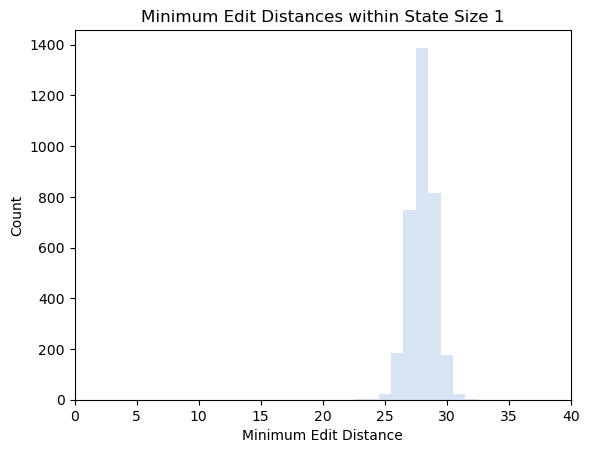

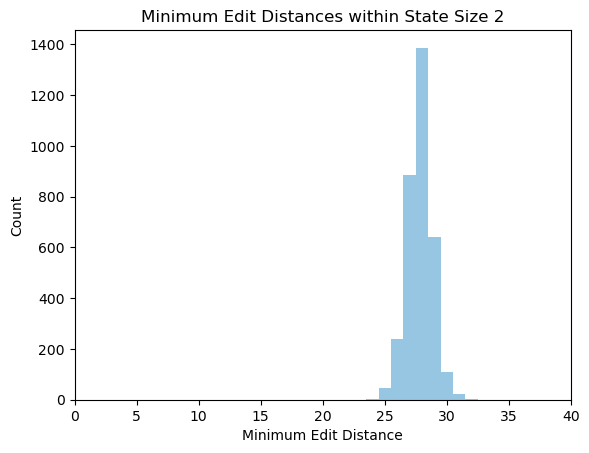

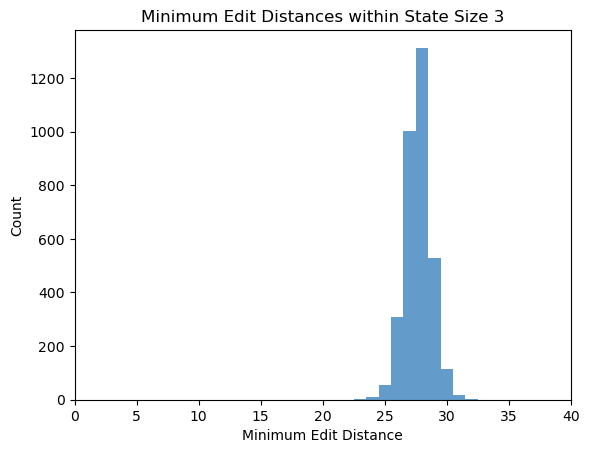

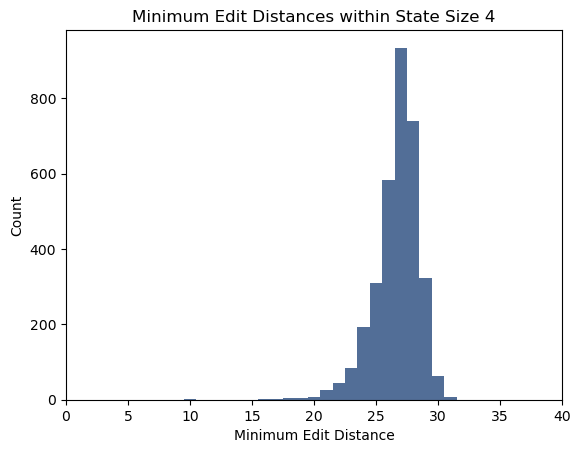

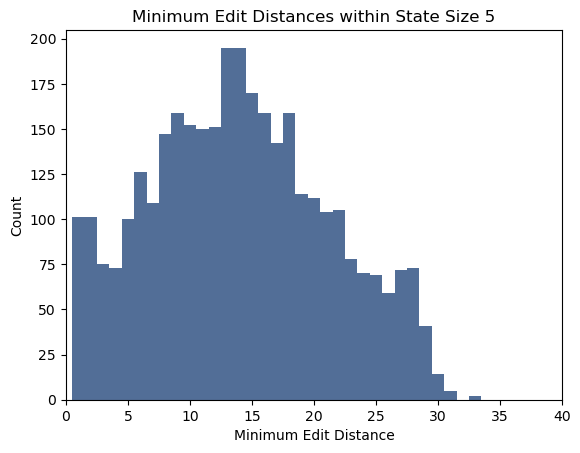

In [102]:
def min_edit_distances_within_group(editdist_df):
    # For each sequence, find the minimum nonzero edit distance to any other sequence in the group
    min_dists = []
    for idx, row in editdist_df.iterrows():
        # Exclude self (distance 0) by replacing 0 with np.nan, then take min
        dists = row.values.copy()
        dists[dists == 0] = np.nan
        min_dist = np.nanmin(dists)
        min_dists.append(min_dist)
    return np.array(min_dists)

# For each state size, get the minimum edit distances
min_dists1 = min_edit_distances_within_group(state1_editdist_df)
min_dists2 = min_edit_distances_within_group(state2_editdist_df)
min_dists3 = min_edit_distances_within_group(state3_editdist_df)
min_dists4 = min_edit_distances_within_group(state4_editdist_df)
min_dists5 = min_edit_distances_within_group(state5_editdist_df)

# Plot histograms
plt.hist(min_dists1, color=blues(0.2), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Minimum Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
plt.title('Minimum Edit Distances within State Size 1')
plt.show()

plt.hist(min_dists2, color=blues(0.4), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Minimum Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
plt.title('Minimum Edit Distances within State Size 2')
plt.show()

plt.hist(min_dists3, color=blues(0.6), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Minimum Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
plt.title('Minimum Edit Distances within State Size 3')
plt.show()

plt.hist(min_dists4, color=blues(0.8), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Minimum Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
plt.title('Minimum Edit Distances within State Size 4')
plt.show()

plt.hist(min_dists5, color=blues(0.99), alpha=0.7, bins=np.linspace(-.5,40.5,42))
plt.xlabel('Minimum Edit Distance')
plt.ylabel('Count')
plt.xlim(0,40)
plt.title('Minimum Edit Distances within State Size 5')
plt.show()

In [60]:
trainpaddle = pd.read_csv(r"C:\Users\music\Downloads\TrainingSeqs_53_Paddle_dask_preds.csv", index_col=0)
trainpaddle['sequence'] = trainpaddle['sequence'].str.replace('^SHLATAGSTSSAS', '', regex=True)
traintada = pd.read_csv(r"C:\Users\music\Downloads\TrainingSeqsTADA_preds.csv", index_col=0)
trainadh = pd.read_csv(r"C:\Users\music\Downloads\TrainingSeqs_ADHunter_preds.csv", index_col=0)
trainadpred = pd.read_csv(r"C:\Users\music\Downloads\TrainingSeqs_ADpred_preds_dask.csv", index_col=0)
trainpaddle

,name,sequence,paddle_centers,paddle_preds
0,0,RYTFRSNARAASGQANANYQAFTAGSALNGPSLPAPSLFA,[27.0],[0.08723831]
1,1,AHSDHSAQRGIRLSGLEAREGTEHPQAHLSPASSRIEVAS,[27.0],[-0.0658319]
2,2,LEAREGTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAAT,[27.0],[0.2303431]
3,3,GTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAATGPAIA,[27.0],[0.22766352]
4,4,PQQTWASYNPVVSNNASASEVRGVPAPEDDFDDAMNLWMG,[27.0],[2.8986633]
...,...,...,...,...
14022,4195,MDAVLEPFPADRLFPGSSFLDLGDLNESDFLNNAHFPEHLDHFTEN...,"[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0]","[10.093962,10.170293,10.243966,10.34363,10.343..."
14023,4196,PAAAAIQRHYNDEDPEKEKRIKELELLLMSTENELKGQQVLPTQNH...,[27.0],[0.27834654]
14024,4198,VRAPSPEEMEEEAIASLPGEETEDMDFLSGLELADLLDPRQPDWHL...,"[27.0,28.0,29.0,30.0,31.0,32.0]","[7.097956,7.073538,7.073538,7.073538,7.073538,..."
14025,4208,EAKGNEVRPVAGSAESAALRLRAPLQQVQAQLSPLQNISPWILAVL...,"[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[-0.005548096,-0.0046069226,-0.0040011066,-0.0..."


In [61]:
def process_preds_column(col):
    # Remove brackets, split by comma, convert to float, average if needed
    def process_cell(cell):
        nums = [x for x in cell.strip('[]').split(',') if x.strip() != '']
        if not nums:
            return np.nan  # or another default value
        nums = [float(x) for x in nums]
        return float(np.mean(nums))
    return col.apply(process_cell)
trainpaddle['paddle_preds'] = process_preds_column(trainpaddle['paddle_preds'])
traintada['tada_preds'] = process_preds_column(traintada['tada_preds'])
trainadh['adhunter_preds'] = process_preds_column(trainadh['adhunter_preds'])
trainadpred['adpred_preds'] = process_preds_column(trainadpred['adpred_preds'])

In [62]:
print(trainpaddle.shape[0], traintada.shape[0], trainadh.shape[0], trainadpred.shape[0])

14027 14892 14799 14907


In [63]:
merged = trainpaddle.merge(traintada, on='sequence', how='inner', suffixes=('_paddle', '_tada'))
merged = merged.merge(trainadh, on='sequence', how='inner', suffixes=('', '_adh'))
merged = merged.merge(trainadpred, on='sequence', how='inner', suffixes=('', '_adpred'))
merged.shape

(63753, 10)

In [64]:
print(trainpaddle['sequence'].duplicated().sum())
print(traintada['sequence'].duplicated().sum())
print(trainadh['sequence'].duplicated().sum())
print(trainadpred['sequence'].duplicated().sum())
trainpaddle = trainpaddle.drop_duplicates(subset='sequence')
traintada = traintada.drop_duplicates(subset='sequence')
trainadh = trainadh.drop_duplicates(subset='sequence')
trainadpred = trainadpred.drop_duplicates(subset='sequence')
for df in [trainpaddle, traintada, trainadh, trainadpred]:
    df['sequence'] = df['sequence'].astype(str).str.strip()
merged = trainpaddle.merge(traintada, on='sequence', how='inner', suffixes=('_paddle', '_tada'))
merged = merged.merge(trainadh, on='sequence', how='inner', suffixes=('', '_adh'))
merged = merged.merge(trainadpred, on='sequence', how='inner', suffixes=('', '_adpred'))
print(merged.shape)

3404
3408
3406
3408
(10623, 10)


C:\Users\music\AppData\Local\Temp\ipykernel_50048\163231684.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sequence'] = df['sequence'].astype(str).str.strip()


In [65]:
merged.drop(columns=['paddle_centers', 'tada_centers', 'adhunter_centers', 'name_adpred', 'name'], inplace=True)
merged

,sequence,paddle_preds,tada_preds,adhunter_preds,adpred_preds
0,RYTFRSNARAASGQANANYQAFTAGSALNGPSLPAPSLFA,0.087238,0.231577,64526.090000,0.003326
1,AHSDHSAQRGIRLSGLEAREGTEHPQAHLSPASSRIEVAS,-0.065832,0.167452,40218.887000,0.000261
2,LEAREGTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAAT,0.230343,0.185201,63376.965000,0.006215
3,GTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAATGPAIA,0.227664,0.180870,62007.176000,0.007494
4,PQQTWASYNPVVSNNASASEVRGVPAPEDDFDDAMNLWMG,2.898663,0.562090,130985.760000,0.255536
...,...,...,...,...,...
10618,MDAVLEPFPADRLFPGSSFLDLGDLNESDFLNNAHFPEHLDHFTEN...,10.332968,0.678975,214074.292381,0.867153
10619,PAAAAIQRHYNDEDPEKEKRIKELELLLMSTENELKGQQVLPTQNH...,0.278347,0.184158,31648.154357,0.014522
10620,VRAPSPEEMEEEAIASLPGEETEDMDFLSGLELADLLDPRQPDWHL...,7.074388,0.639355,115767.150158,0.467664
10621,EAKGNEVRPVAGSAESAALRLRAPLQQVQAQLSPLQNISPWILAVL...,-0.003830,0.201291,60913.719971,0.041250


In [ ]:
merged.to_csv(r"C:\Users\music\Downloads\TrainingSeqs_Preds_innermerge.csv")
# editdist_df.to_csv(r"C:\Users\music\Downloads\SynthSeqs_EditDistancesMatrix.csv")

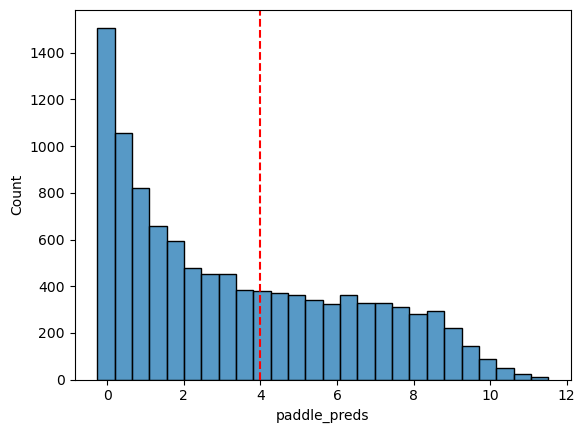

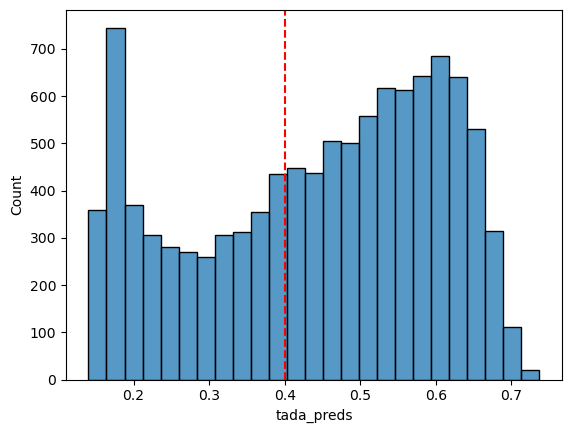

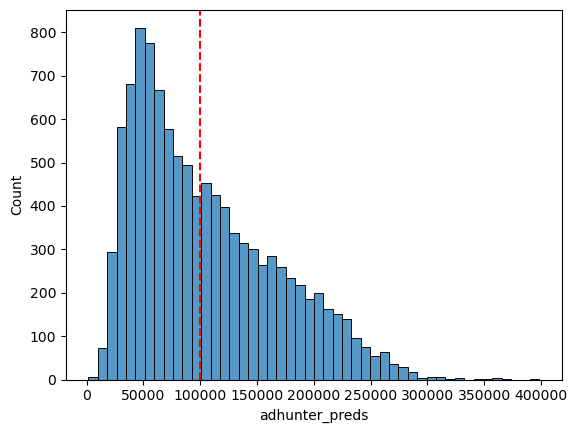

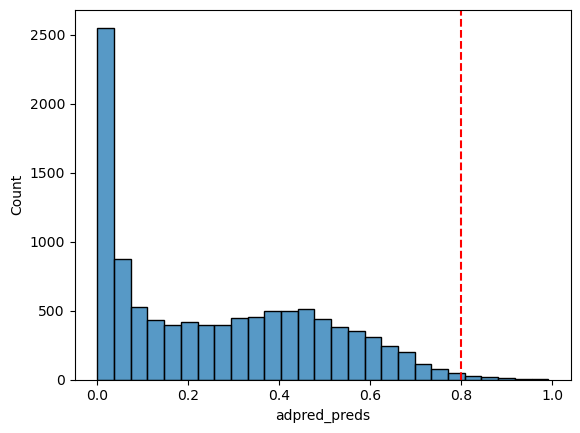

In [70]:
sns.histplot(merged['paddle_preds'])
plt.axvline(x=4, color='red', linestyle='--')
plt.show()
sns.histplot(merged['tada_preds'])
plt.axvline(x=00.4, color='red', linestyle='--')
plt.show()
sns.histplot(merged['adhunter_preds'])
plt.axvline(x=100000, color='red', linestyle='--')
plt.show()
sns.histplot(merged['adpred_preds'])
plt.axvline(x=0.8, color='red', linestyle='--')
plt.show()

In [36]:
trainadpred

,name,sequence,adpred_preds
0,0,RYTFRSNARAASGQANANYQAFTAGSALNGPSLPAPSLFA,"[8.930743e-05,7.780824e-05,6.955658e-05,6.9746..."
1,1,AHSDHSAQRGIRLSGLEAREGTEHPQAHLSPASSRIEVAS,"[0.00013366516,0.00021121166,0.0002629882,0.00..."
2,2,LEAREGTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAAT,"[0.00017133498,0.00019955078,0.00025247087,0.0..."
3,3,GTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAATGPAIA,"[0.00010051464,0.00014829946,0.00016221633,0.0..."
4,4,PQQTWASYNPVVSNNASASEVRGVPAPEDDFDDAMNLWMG,"[0.0012925317,0.0010954087,0.001134463,0.00126..."
...,...,...,...
14902,14906,RNGHNLGLSLGESSSEEFRLKSDIASIRSRIRDEERLLGS,"[0.00045715662,0.0005319795,0.00074737926,0.00..."
14903,14907,NFISRLRSLYNYMWIPYDTAEMFLTRGSEQRQWYEADISW,"[0.098548494,0.06922218,0.1297264,0.16392025,0..."
14904,14908,NYMWIPYDTAEMFLTRGSEQRQWYEADISWKIDNVVAKEG,"[0.3328625,0.19335961,0.20867877,0.2550714,0.3..."
14905,14909,TPSSTRRRSVTPSMNSEDSGTTTTTTAFCDKGDVYGNGGG,"[4.3690976e-05,3.1040436e-05,3.5870875e-05,4.4..."


In [31]:
trainadpred

,name,sequence,adpred_preds
0,0,RYTFRSNARAASGQANANYQAFTAGSALNGPSLPAPSLFA,"[8.930743e-05,7.780824e-05,6.955658e-05,6.9746..."
1,1,AHSDHSAQRGIRLSGLEAREGTEHPQAHLSPASSRIEVAS,"[0.00013366516,0.00021121166,0.0002629882,0.00..."
2,2,LEAREGTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAAT,"[0.00017133498,0.00019955078,0.00025247087,0.0..."
3,3,GTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAATGPAIA,"[0.00010051464,0.00014829946,0.00016221633,0.0..."
4,4,PQQTWASYNPVVSNNASASEVRGVPAPEDDFDDAMNLWMG,"[0.0012925317,0.0010954087,0.001134463,0.00126..."
...,...,...,...
14902,14906,RNGHNLGLSLGESSSEEFRLKSDIASIRSRIRDEERLLGS,"[0.00045715662,0.0005319795,0.00074737926,0.00..."
14903,14907,NFISRLRSLYNYMWIPYDTAEMFLTRGSEQRQWYEADISW,"[0.098548494,0.06922218,0.1297264,0.16392025,0..."
14904,14908,NYMWIPYDTAEMFLTRGSEQRQWYEADISWKIDNVVAKEG,"[0.3328625,0.19335961,0.20867877,0.2550714,0.3..."
14905,14909,TPSSTRRRSVTPSMNSEDSGTTTTTTAFCDKGDVYGNGGG,"[4.3690976e-05,3.1040436e-05,3.5870875e-05,4.4..."


In [37]:
trainadh

,sequence,adhunter_centers,adhunter_preds
name,,,
0,RYTFRSNARAASGQANANYQAFTAGSALNGPSLPAPSLFA,[20.0],[64526.09]
1,AHSDHSAQRGIRLSGLEAREGTEHPQAHLSPASSRIEVAS,[20.0],[40218.887]
2,LEAREGTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAAT,[20.0],[63376.965]
3,GTEHPQAHLSPASSRIEVASWAHEFQRLAPNIAATGPAIA,[20.0],[62007.176]
4,PQQTWASYNPVVSNNASASEVRGVPAPEDDFDDAMNLWMG,[20.0],[130985.76]
...,...,...,...
14906,RNGHNLGLSLGESSSEEFRLKSDIASIRSRIRDEERLLGS,[20.0],[35397.55]
14907,NFISRLRSLYNYMWIPYDTAEMFLTRGSEQRQWYEADISW,[20.0],[81893.45]
14908,NYMWIPYDTAEMFLTRGSEQRQWYEADISWKIDNVVAKEG,[20.0],[72691.84]
